# LangGraph 基础入门


## 阅读路线与状态模型

课程原文的章节编号 1～3 保留，方便回查。先理解状态、节点和边，再读一个完整图的构建过程，最后看 Schema、Reducer 和消息状态。

| 抽象 | 回答的问题 | 一句话理解 |
| --- | --- | --- |
| State（状态） | 当前有哪些数据？ | 图运行时的消息、输入和中间结果 |
| Node（节点） | 当前要做什么？ | 读取状态，执行业务，返回局部更新 |
| Edge（边） | 接下来走哪里？ | 用固定或条件连接触发后续节点 |
| Reducer（合并函数） | 新更新怎样与旧值合并？ | 按字段定义替换、追加或消息更新规则 |

**Schema** 是字段和类型的描述；**Runtime** 是负责调度节点、合并更新和管理执行的运行时。模型调用只是节点的一种业务逻辑，LangGraph 也可以编排不调用模型的流程。

本篇代码都只作阅读示例，不会在 Notebook 中执行。原课程输出删去无关 ID 和长日志，精简的示意输出会注明省略范围。


## 1.0. `LangGraph`和`LangChain`的版本迭代及定位


LangGraph 运行时底层基于自研的 Pregel 运行时，其核心思想借鉴了 Google Pregel 计算模型，用于组织和执行复杂的图计算流程。


**LangChain 1.x** 的定位发生了明显变化：旧式 Chain、Retriever、Memory 等组件被迁移至 langchain-classic；LCEL 保留为 langchain-core 的底层组合机制，但不再是主要开发入口。

**LangChain 1.x** 现在聚焦于 Agent 开发，核心入口是 create_agent，围绕 Agent 提供模型、工具、消息、结构化输出、Middleware（中间件，用于介入 Agent 执行过程）和记忆管理等高层抽象。

**LangGraph** 是更底层的编排框架与 Agent Runtime，负责复杂工作流和有状态 Agent 的执行，提供持久化、流式输出、Durable Execution、Human-in-the-loop 等运行时能力。create_agent 底层基于 LangGraph 实现。

二者的定位对比如下： 

| 对比维度 | LangChain      | LangGraph                    |
| ---- | -------------- | ---------------------------- |
| 定位   | Agent 高层开发框架   | 底层编排框架 & Agent Runtime       |
| 核心入口 | `create_agent` | `StateGraph` / `@entrypoint` |
| 适用场景 | 结构直接的 Agent 应用 | 复杂工作流、持久化状态、长时间运行、人工介入       |
| 流程控制 | Agent 循环自动管理   | 精细控制节点、边、条件分支                |
| 学习成本 | 较低             | 较高                           |

> `LangChain` 提供易于使用的 Agent 高层抽象，`LangGraph` 提供可靠、可持久化且可精细控制的底层执行能力。

对于大多数 Agent 项目，从 LangChain 的 create_agent 开始即可；需要复杂工作流编排、确定性步骤与 Agent 步骤混合、长时间运行或底层状态控制时，再引入 LangGraph。

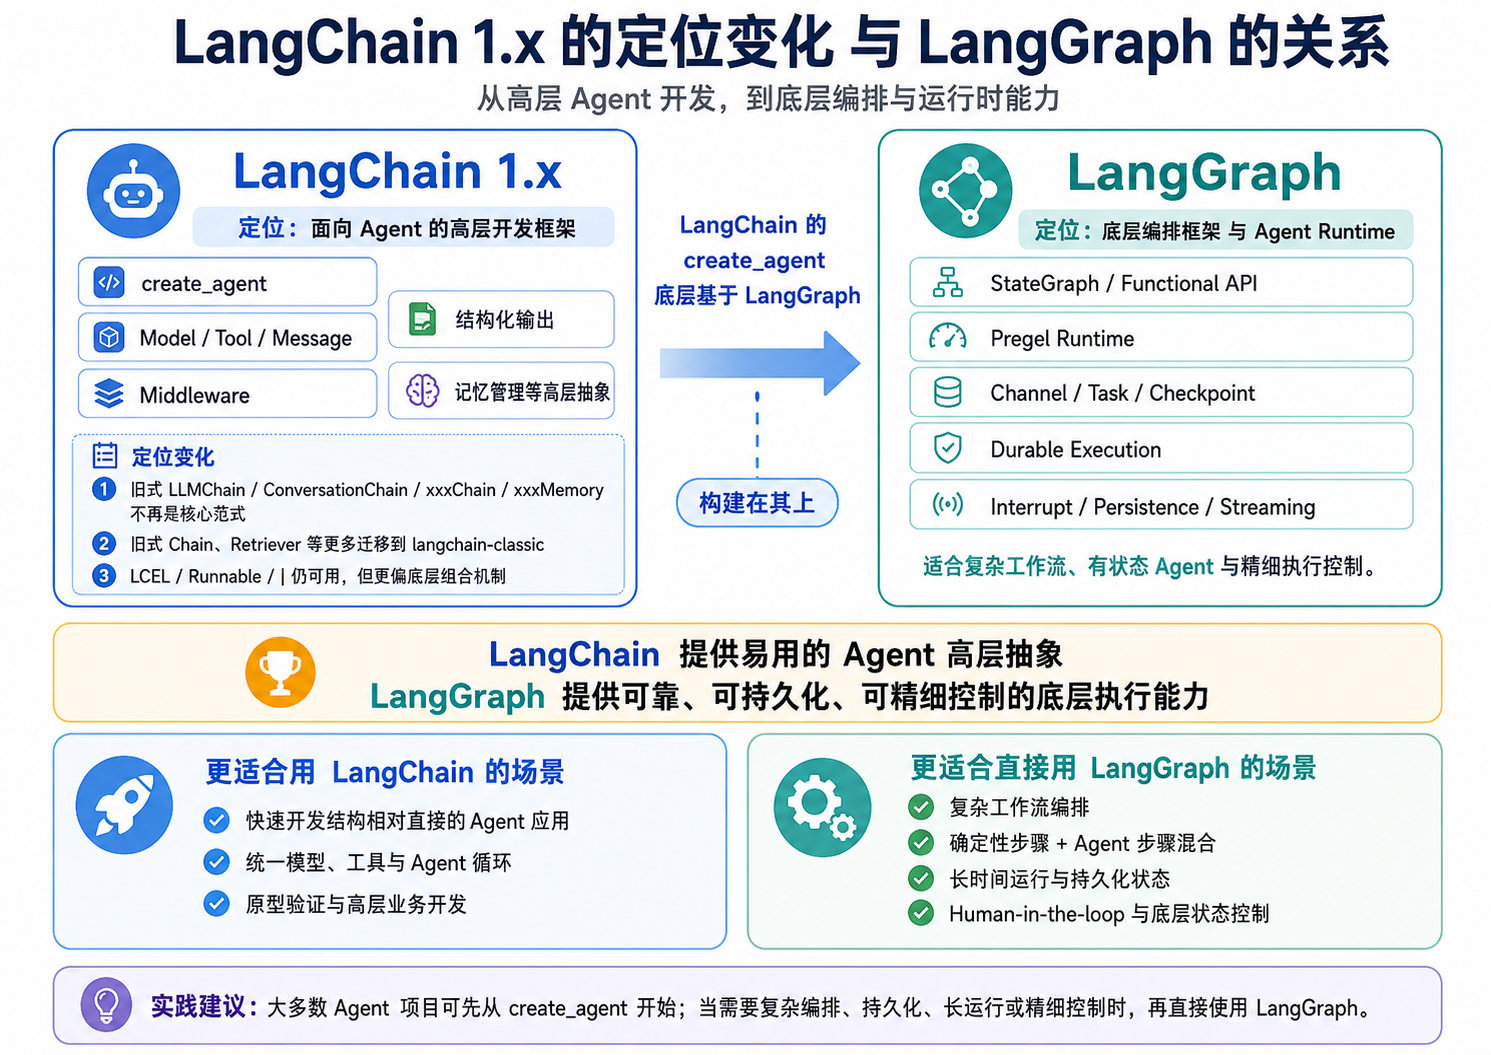


## 1.1. 构成图的基本要素

LangGraph 运行时主要由三个基本要素构成：State（状态）、Node（节点） 和 Edge（边）

State（状态）：LangGraph 运行过程中的共享数据结构，用于表示应用在某一时刻的状态快照。它承载了图运行所需的上下文信息、中间结果和后续节点需要读取的数据，是节点之间传递信息的核心载体。基于 LangGraph 构建的 LangChain Agent 也通过这种状态结构维护消息和中间结果。

Node（节点）：LangGraph 中的具体执行单元，通常实现为一个函数。节点会读取当前 State，执行相应的业务逻辑，并返回对 State 的局部更新。节点本身并不直接修改全局状态，状态的合并与提交由运行时统一完成。

Edges（边）：用于定义节点之间的流转关系，决定一个节点执行完成后下一步应该进入哪个节点。Edge 可以是固定流转，也可以根据当前 State 进行条件判断，从而实现分支、循环等复杂控制流程。

下图展示了一个非常简单的运行图，只有两个计算节点，其拓扑结构为


```text
START --> node_1 --> node_2 --> END
```


如下图所示

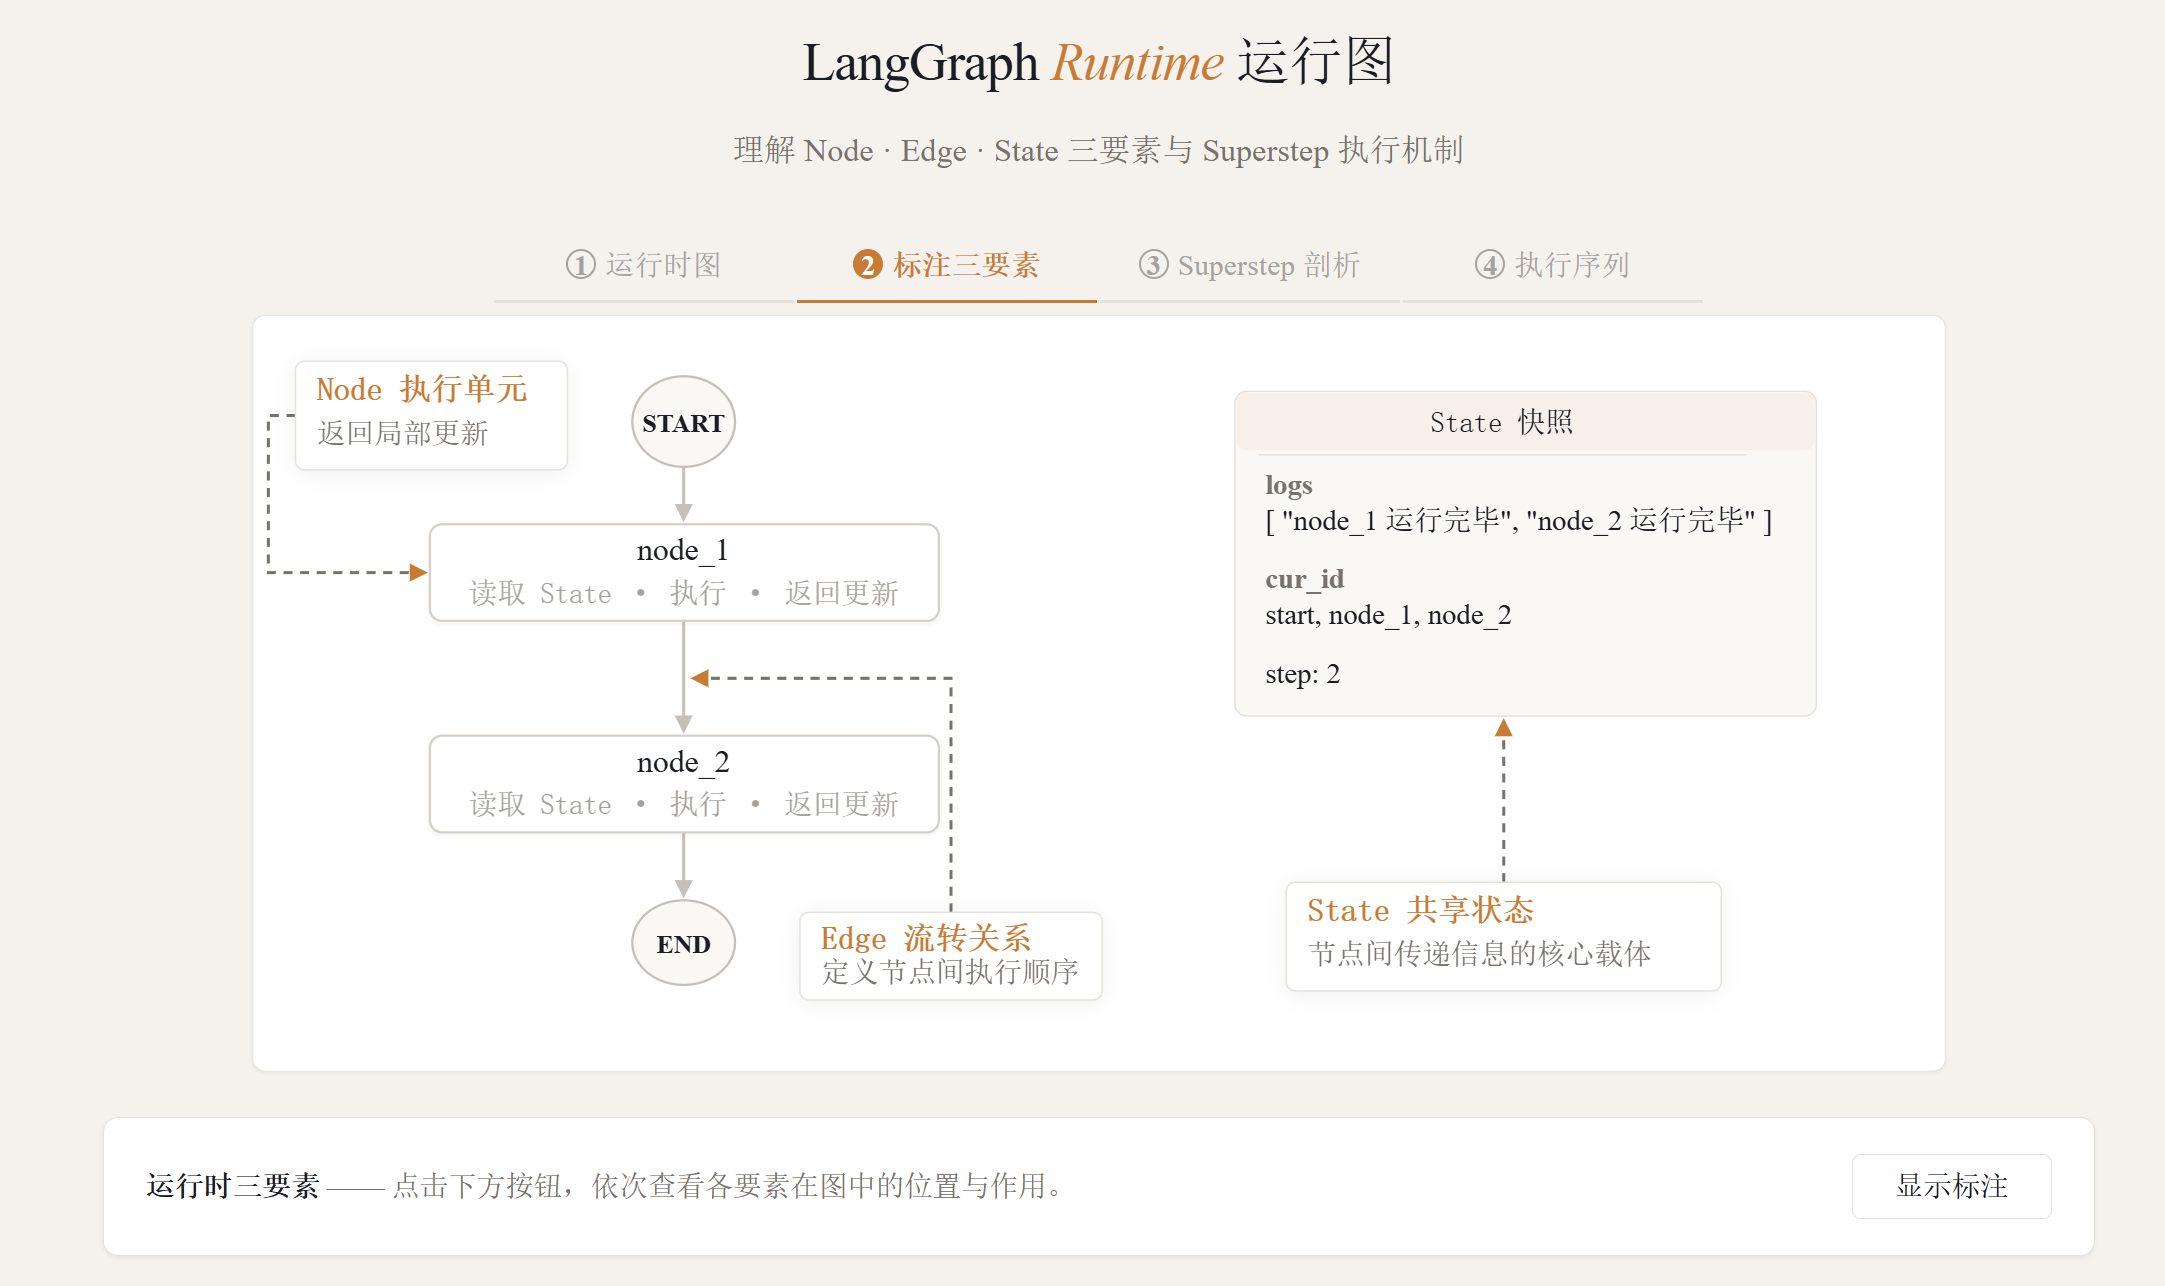


## 1.2. 图运行过程

LangGraph 的图运行过程基于 Superstep（超步） 来组织和推进。Superstep 可以理解为图运行过程中的一次”单步循环”。一次图运行过程从开始到结束，就是由一系列连续的 Superstep 串联而成。

下文以 **node_1执行完毕后的Superstep** 为例说明。

每个 Superstep 通常可以分为三个阶段：

1. 计划/路由阶段（Plan / Routing）：根据当前的 State（状态） 和 Edge（边） 的逻辑，确定本轮超步中应该被执行的节点。

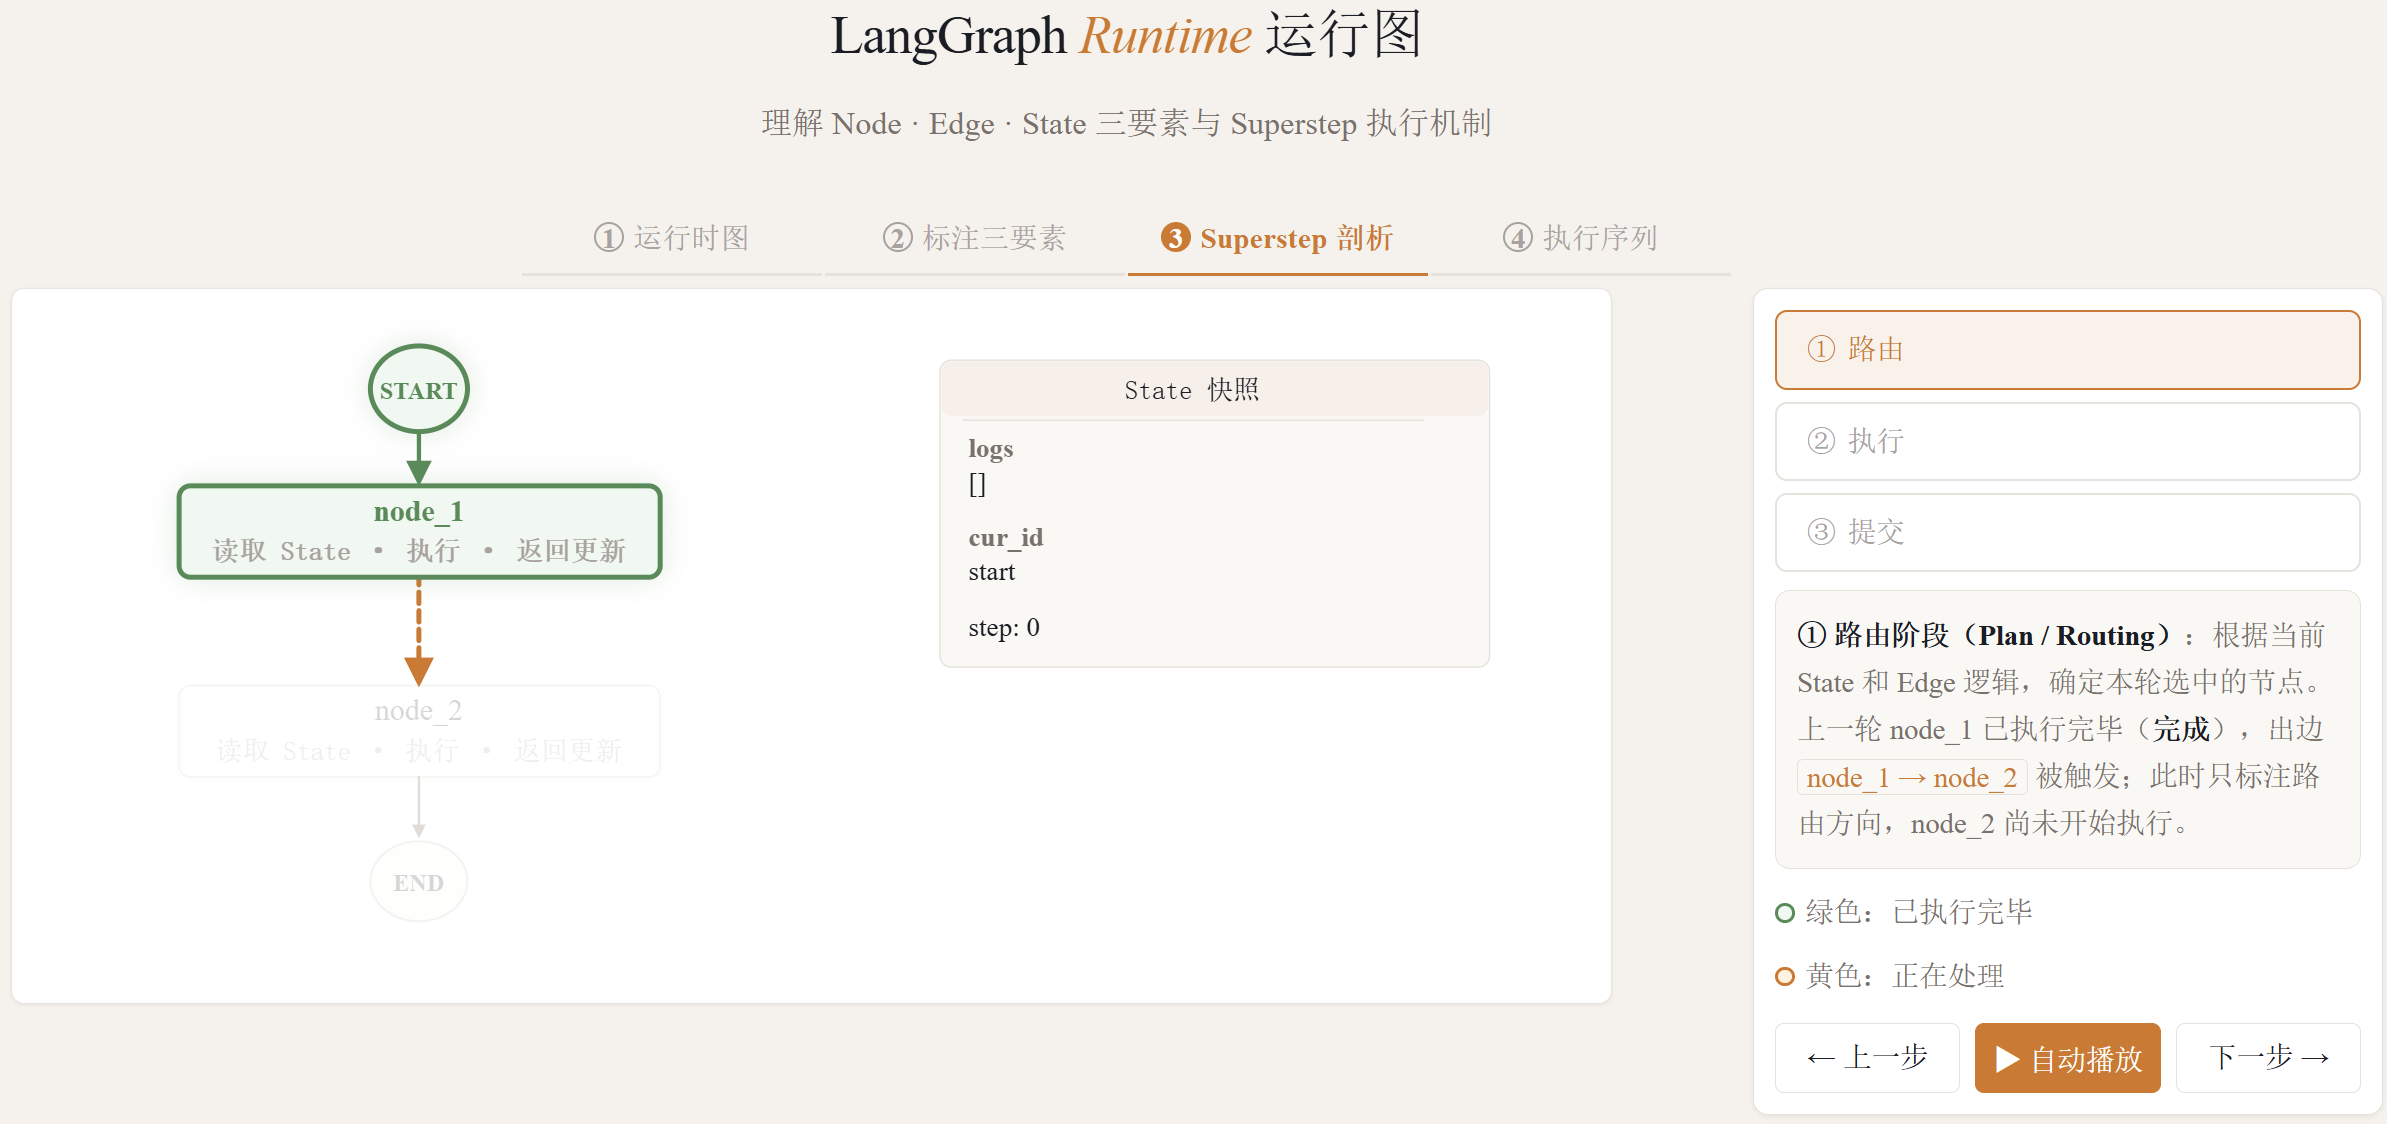

2. 执行阶段（Execution）：运行本轮被选中的节点。如果本轮有多个节点同时被触发，它们会并行执行。每个节点都会基于本轮开始时的状态快照进行计算，并输出各自对状态的局部更新。在本阶段中，一个节点产生的更新不会立即被其他节点读取到。

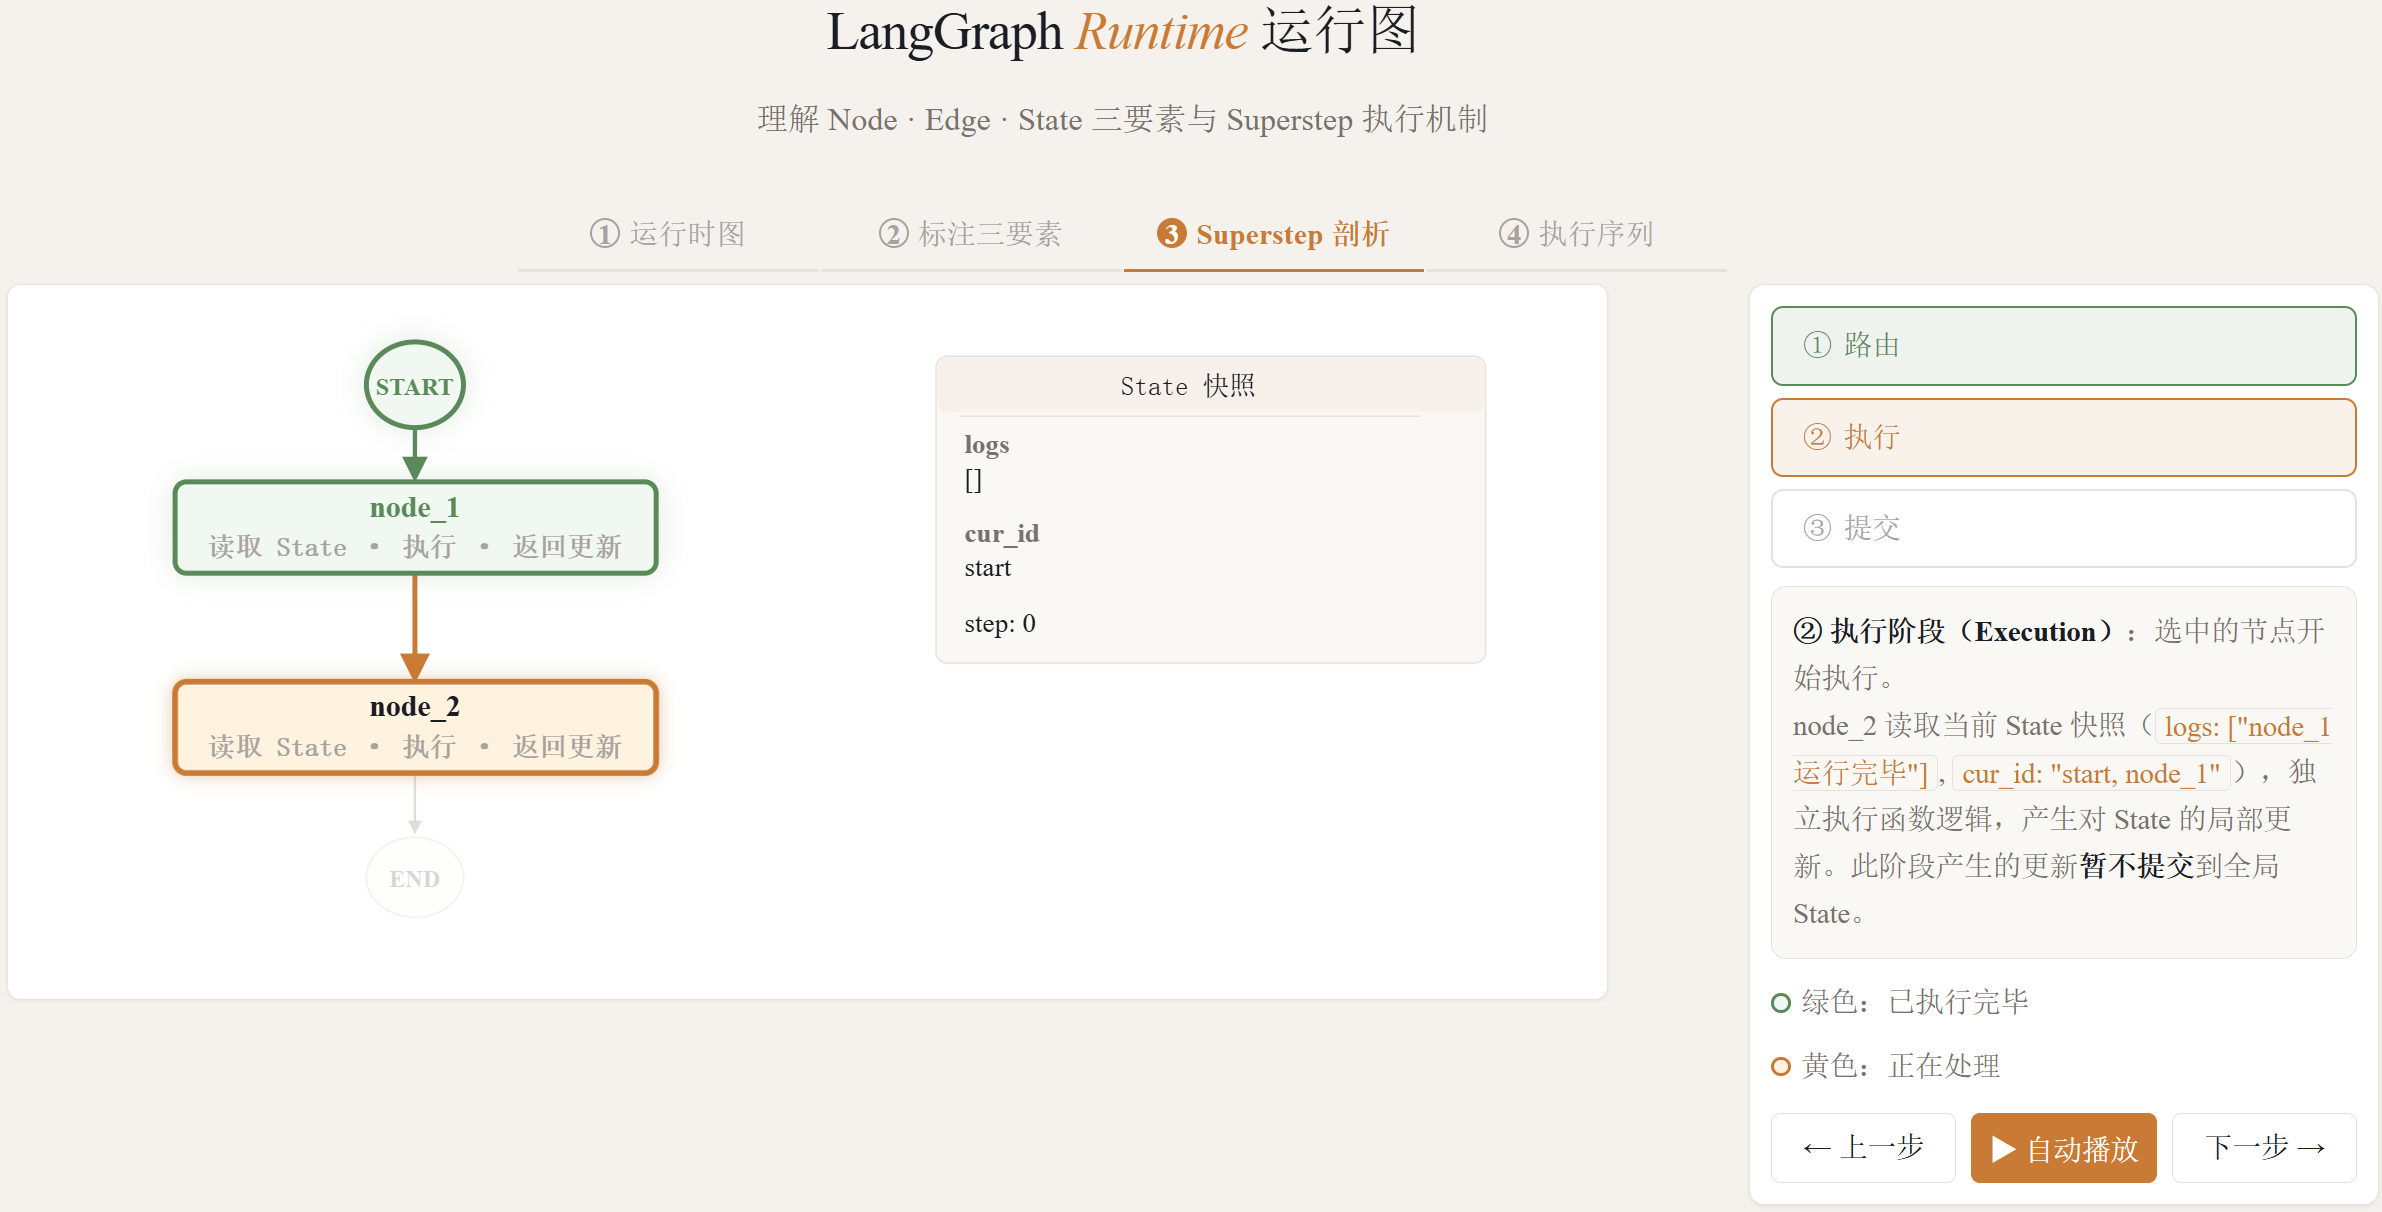

3. 状态更新/提交阶段（Update / Commit）：当本轮所有节点都执行完成后，LangGraph 会将它们的输出统一合并到 State 中，生成新的状态快照。这个新状态会作为下一轮 Superstep 的输入。

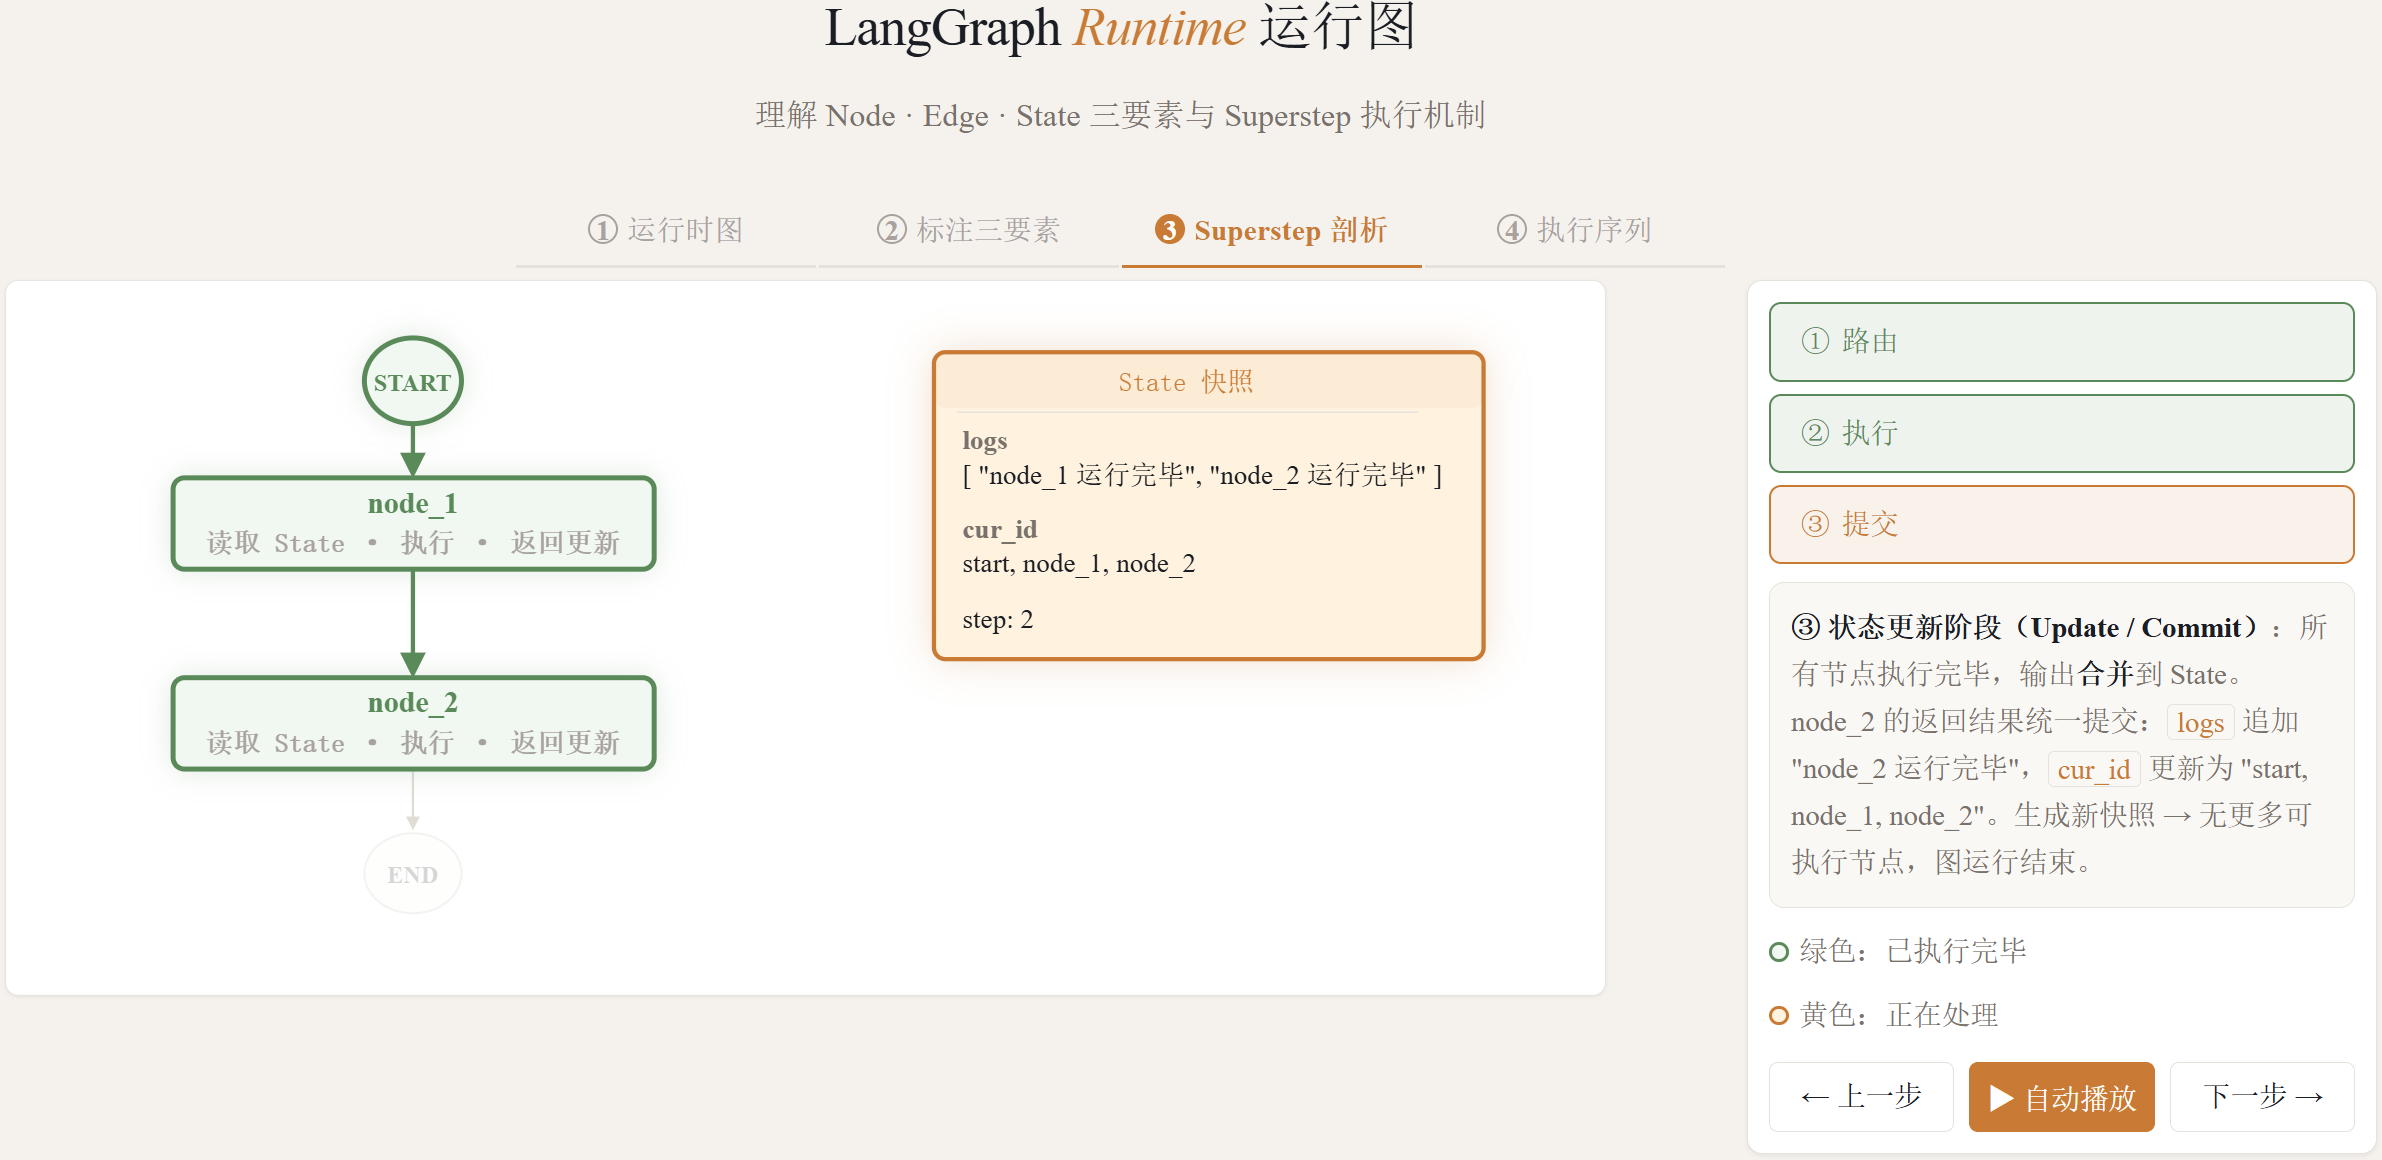

完整的运行流程查看 [index.html](langgraph-runtime-viz/index.html) ，双击在浏览器打开即可。

其中和Checkpoint相关的部分，学习相关内容后再看。


## 1.3. Graph API vs Functional API

LangGraph 提供了两种不同的 API 来构建运行图：`Graph API`（图式 API） 和 `Functional API`（函数式 API）。这两种 API 共享相同的底层运行时，可以在同一应用程序中协同使用，但它们针对不同的使用场景和开发偏好而设计。

------


## 1.3.1. Graph API

Graph API 采用声明式方式构建工作流。开发者需要显式定义 State、Node 和 Edge，将业务流程组织成一个可视化的图结构。

当流程中存在较复杂的分支、多个节点之间共享状态、并行执行、结果汇聚，或者需要通过图结构帮助调试和团队协作时，更适合使用 Graph API。官方文档也明确建议，在需要复杂流程可视化、显式状态管理、多条件分支、并行路径以及团队协作时，优先选择 Graph API。

总之：

> Graph API 更适合构建结构清晰、节点关系复杂、需要长期维护的工作流。

典型场景包括：

| 场景        | 说明                        |
| --------- | ------------------------- |
| 多节点复杂流程   | 流程中存在多个处理节点，需要清晰表达节点之间的关系 |
| 条件分支较多    | 根据 State 中的不同字段决定后续执行路径   |
| 并行执行与结果汇聚 | 多个节点并行运行，之后汇总结果           |
| 多组件共享状态   | 多个节点都需要读写同一个全局 State      |
| 需要图结构展示   | 便于调试、讲解、文档化和团队协作          |

------


## 1.3.2. Functional API

Functional API 采用命令式方式构建工作流，更接近普通 Python 函数调用。开发者可以使用 `@entrypoint` 定义工作流入口，使用 `@task` 定义可被检查点记录的任务，然后在函数内部使用普通的 `if/else`、循环和函数调用来组织流程。官方文档指出，当已有过程式代码需要最小改造、流程主要是线性的、分支逻辑较简单、希望快速原型验证时，更适合使用 Functional API。

可以这样理解：

> Functional API 更适合在普通 Python 函数流程中，以较低成本接入 LangGraph 的持久化、中断恢复和任务记录能力。

典型场景包括：

| 场景      | 说明                        |
| ------- | ------------------------- |
| 现有代码改造  | 原本已有函数式或过程式代码，不希望重构成完整图结构 |
| 线性流程    | 主要是 A → B → C 的顺序执行       |
| 简单分支    | 只有少量 `if/else` 判断         |
| 快速原型验证  | 希望减少样板代码，快速验证业务逻辑         |
| 局部任务持久化 | 希望某些函数作为独立 task 被检查点记录    |

------


## 1.3.3. 二者的核心区别

| 对比项   | Graph API       | Functional API    |
| ----- | --------------- | ----------------- |
| 编程风格  | 声明式图结构          | 命令式函数流程           |
| 核心抽象  | State、Node、Edge | entrypoint、task   |
| 状态管理  | 显式定义全局 State    | 更多依赖函数参数和返回值      |
| 流程表达  | 通过节点和边表达        | 通过普通 Python 控制流表达 |
| 可视化能力 | 强，天然适合画图和调试     | 弱，更像普通代码流程        |
| 适合场景  | 复杂工作流、多分支、多节点协作 | 简单流程、快速原型、已有代码改造  |
| 学习成本  | 相对更高            | 相对更低              |

------


## 1.3.4. 选型建议

从零构建或流程结构复杂，用 `Graph API`；现有代码改造、快速原型验证或流程逻辑简单，用 `Functional API`。

学习 `LangGraph` 建议优先掌握 `Graph API`。因为后者更能体现 `LangGraph` 的核心思想：通过 `State、Node、Edge` 显式描述一个可执行的计算图。

本文介绍 `Graph API`，对 `Functional API` 感兴趣的同学自行查阅

> https://docs.langchain.com/oss/python/langgraph/functional-api


## 2.1. 定义状态图


本节将从一个基础案例入手，掌握图的基本创建、调用和可视化方法。

图的构建与运行分为三个阶段：定义状态图、编译状态图、调用状态图


状态图的定义可以分为以下几个步骤：

**1. 定义全局状态**  定义整个运行图共享的全局状态（实际上，除了全局状态，LangGraph还支持其它类型的状态，下文详述）

**2. 创建状态图**     创建 StateGraph实例，将状态和状态图绑定

**3. 定义图结构**     定义节点和边并添加到状态图中


## 2.1.1. 定义全局状态

图状态是节点之间共享数据的载体。节点默认读取图状态，也可以通过自己的输入 Schema 限定可读字段，因此不必把全部内部字段暴露给每个节点。这里的 `logs` 用追加规则收集日志，`cur_id` 在顺序执行时由新值替换旧值。


```python
class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    cur_id: str
```


## 2.1.2. 创建状态图

`StateGraph` 是图的构建器：先绑定状态字段及其合并规则，再注册节点和边。创建构建器不会执行节点；只有编译后调用图才开始运行。

```python
builder = StateGraph(state_schema=OverAllState)
```


## 2.1.3. 定义图结构

### 2.1.3.1. 定义图节点


```python
def node_1(state: OverAllState) -> OverAllState:
    pre_id = state["cur_id"]
    return {
        "logs": ["node_1 运行完毕"],
        "cur_id": pre_id + ", node_1"
    }

def node_2(state: OverAllState) -> OverAllState:
    pre_id = state["cur_id"]
    return {
        "logs": ["node_2 运行完毕"],
        "cur_id": pre_id + ", node_2"
    }
```


### 2.1.3.2. 添加节点


```python
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
```


### 2.1.3.3. 添加边


```python
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", END)
```


## 2.2. 编译状态图

将上一步得到的状态图编译为可执行的运行图


```python
graph = builder.compile()
```


## 2.3. 调用状态图

可以通过invoke调用计算图


```python
print(graph.invoke({"cur_id": "start"}))
```


## 2.4. 完整代码

这个顺序图演示两种更新方式：`logs` 追加各节点新增的日志，`cur_id` 则依次替换。节点返回局部更新，不需要把旧日志再放回返回值。

```python
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from operator import add

class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    cur_id: str

def node_1(state: OverAllState) -> OverAllState:
    pre_id = state["cur_id"]
    return {
        "logs": ["node_1 运行完毕"],
        "cur_id": pre_id + ", node_1"
    }

def node_2(state: OverAllState) -> OverAllState:
    pre_id = state["cur_id"]
    return {
        "logs": ["node_2 运行完毕"],
        "cur_id": pre_id + ", node_2"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", END)

graph = builder.compile()

print(graph.invoke({"cur_id": "start"}))
```


```text
{'logs': ['node_1 运行完毕', 'node_2 运行完毕'], 'cur_id': 'start, node_1, node_2'}
```


## 2.5.1. 绘制mermaid并获取源码


mermaid是一种生成图表和流程图的文本标记语言，它可以把简单的文本描述直接渲染成可视化图形。

通过以下代码可以用mermaid语法表达图结构，并打印mermaid源码


```python
raw_mermaid = graph.get_graph().draw_mermaid()
print(raw_mermaid)
```


```text
---
config:
  flowchart:
    curve: linear
---
graph TD;
    __start__([<p>__start__</p>]):::first
    node_1(node_1)
    node_2(node_2)
    __end__([<p>__end__</p>]):::last
    __start__ --> node_1;
    node_1 --> node_2;
    node_2 --> __end__;
    classDef default fill:#f2f0ff,line-height:1.2
    classDef first fill-opacity:0
    classDef last fill:#bfb6fcmermaidmermain
```


输出文本从`graph TD;`开始的部分为mermaid源码。


```mermaid
graph TD;
    __start__([<p>__start__</p>]):::first
    node_1(node_1)
    node_2(node_2)
    __end__([<p>__end__</p>]):::last
    __start__ --> node_1;
    node_1 --> node_2;
    node_2 --> __end__;
    classDef default fill:#f2f0ff,line-height:1.2
    classDef first fill-opacity:0
    classDef last fill:#bfb6fc
```


## 2.5.2. 绘制mermaid并转换为png

Langgraph也支持将mermaid转换为图片字节流


```python
png_bytes = graph.get_graph().draw_mermaid_png()
```


`draw_mermaid_png()`底层会先调用`draw_mermaid()`得到mermaid语法的图表代码，然后调用在线服务渲染为mermaid图片。

默认的mermaid在线渲染服务链接为：https://mermaid.ink，由于网络问题可能存在渲染失败的情况，通常重试即可成功。

可以通过`draw_mermaid_png()`的`base_url`参数替换可用的mermaid在线渲染服务，

### 2.5.2.1. jupyter环境下直接展示图片

在jupyter环境下，可以通过IPython提供的功能将图片字节流直接展示为图片。


```python
from IPython.display import display, Image

png_bytes = graph.get_graph().draw_mermaid_png()
png = Image(png_bytes)
display(png)
```


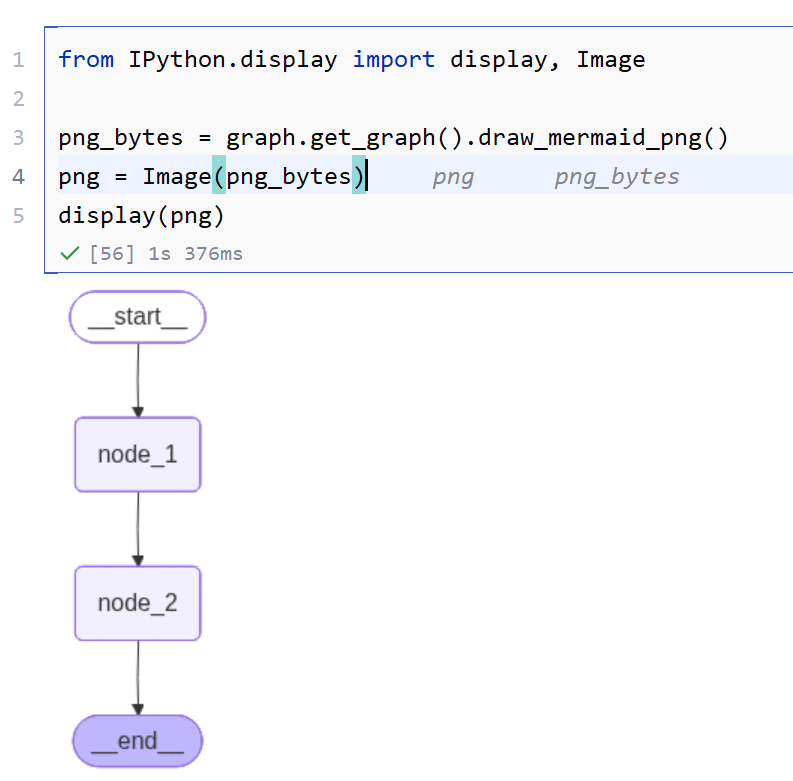

### 2.5.2.2. 保存为图片文件

也可以将图片字节流转换为PNG文件落盘


```python
png_bytes = graph.get_graph().draw_mermaid_png()
png_filename = 'first_demo_graph.png'
with open(png_filename, "wb") as f:
    f.write(png_bytes)
```


运行结束后，代码文件同级目录下将会出现生成好的图片文件，如下图所示。

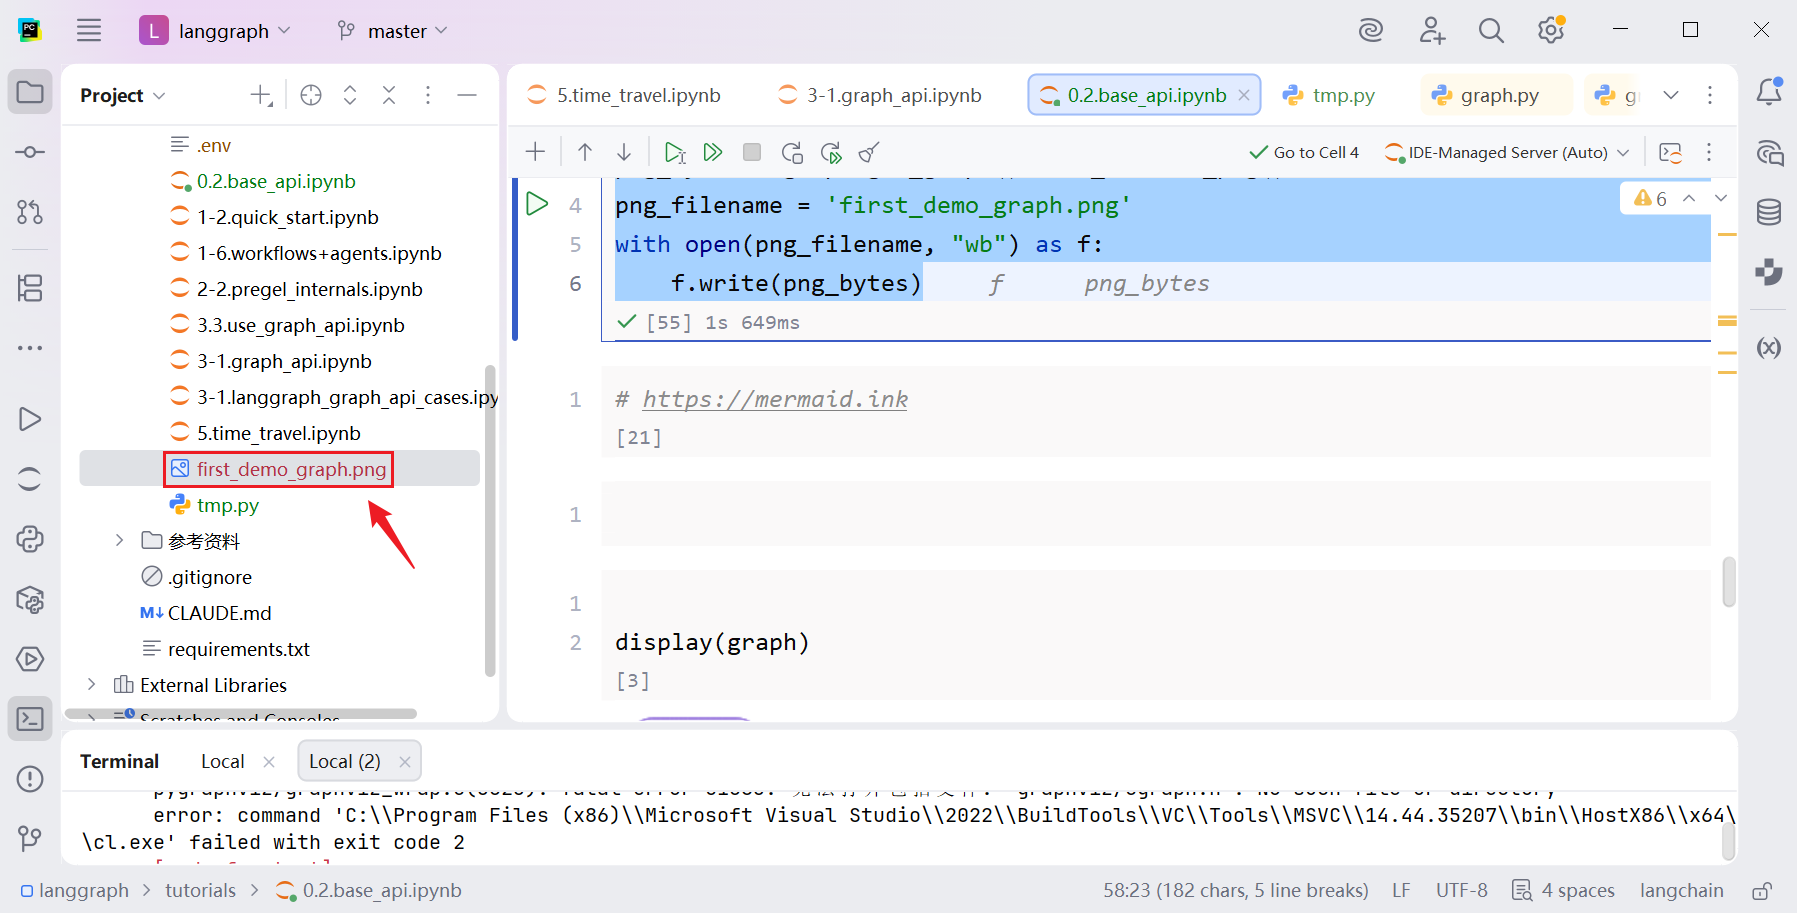

如果看不到文件，可以刷新上级目录

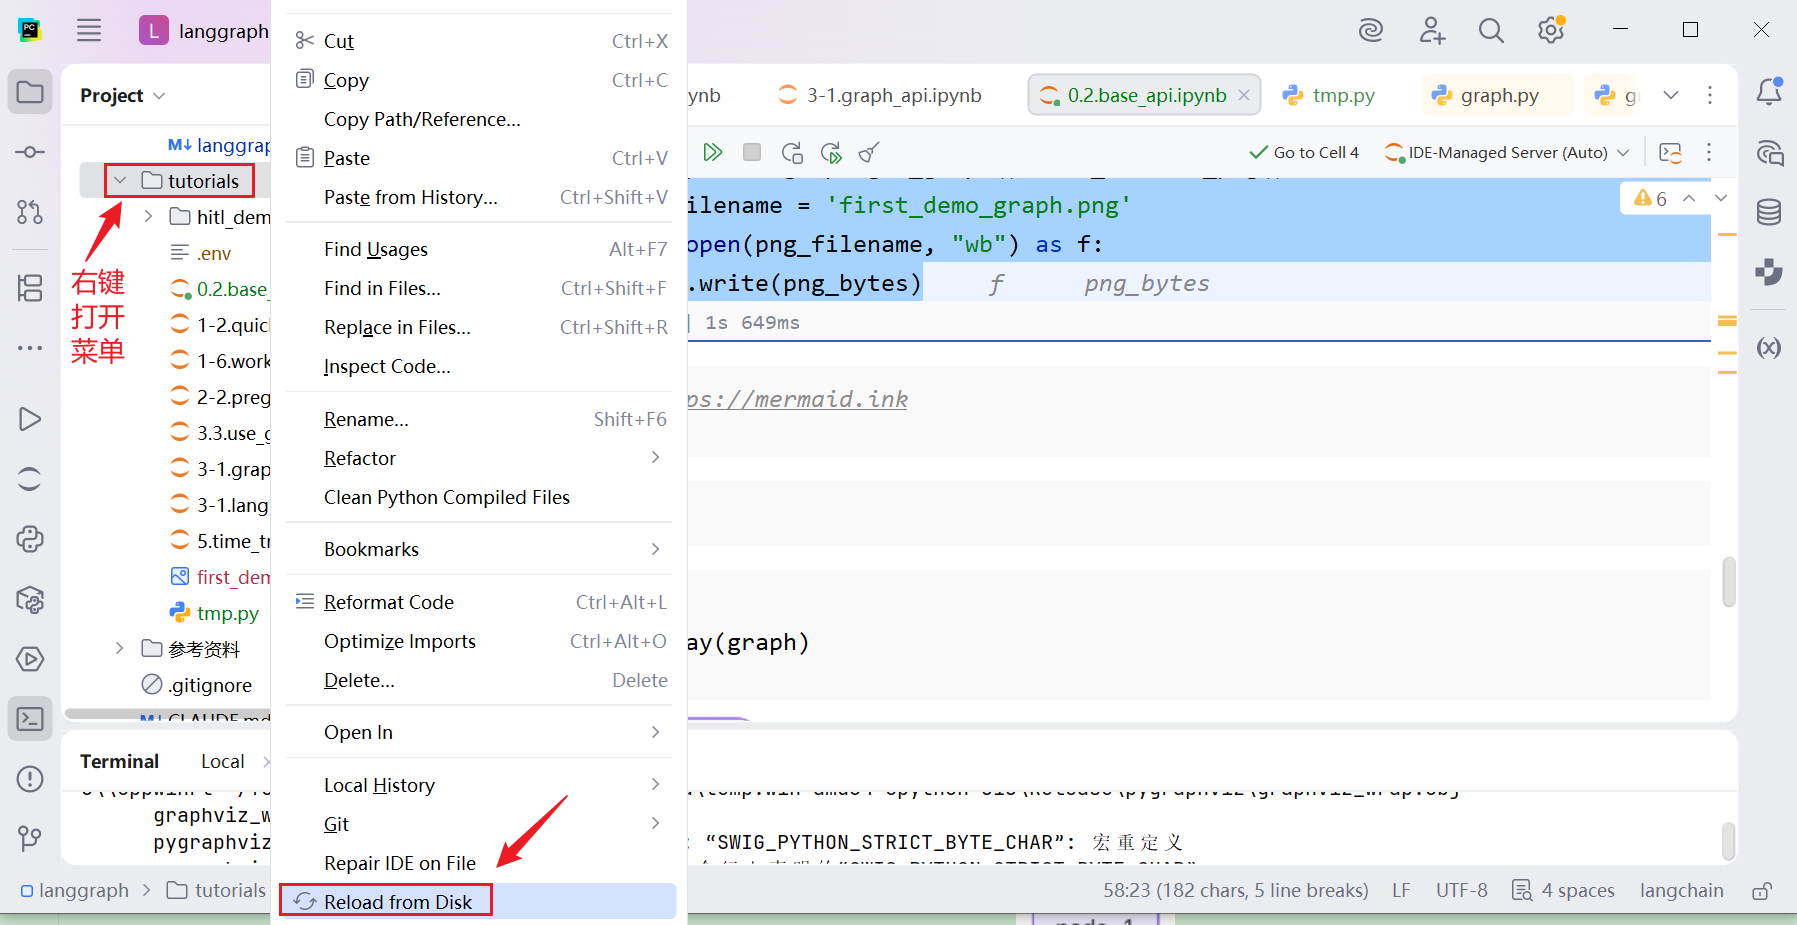

图片内容如下

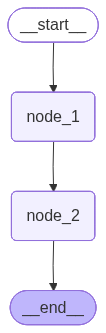

### 2.5.2.3. 快捷用法

在 `Jupyter` 环境下，可以直接使用 `display(graph)` 快速展示编译后的图结构：


```python
from IPython.display import display

display(graph)
```


效果如下

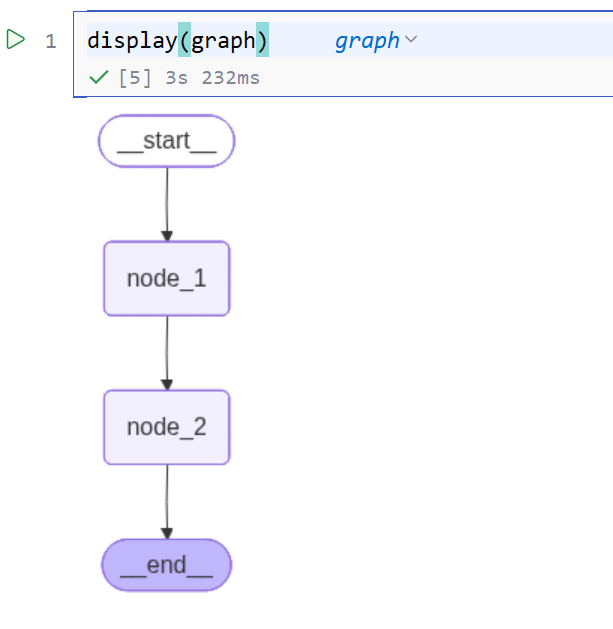


## 3.1.1. TypedDict


状态的定义实际上是在声明状态的Schema，后者是状态字段的完整描述。

官方推荐了三种定义Schema的方式：TypedDict、dataclass、Pydantic


```python
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from operator import add

class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    cur_id: str

def node_1(state: OverAllState) -> OverAllState:
    pre_id = state["cur_id"]
    return {
        "logs": ["node_1 运行完毕"],
        "cur_id": pre_id + ", node_1"
    }

def node_2(state: OverAllState) -> OverAllState:
    pre_id = state["cur_id"]
    return {
        "logs": ["node_2 运行完毕"],
        "cur_id": pre_id + ", node_2"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", END)

graph = builder.compile()

print(graph.invoke({"cur_id": "start"}))
```


输出


```text
{'logs': ['node_1 运行完毕', 'node_2 运行完毕'], 'cur_id': 'start, node_1, node_2'}
```


## 3.1.2. dataclass

属性调用方式由`['字段名']`变为`.字段名`。


```python
from langgraph.graph import StateGraph, START, END
from typing import Annotated
from dataclasses import dataclass
from operator import add

@dataclass
class OverAllState:
    logs: Annotated[list[str], add]
    cur_id: str

def node_1(state: OverAllState) -> OverAllState:
    pre_id = state.cur_id
    return {
        "logs": ["node_1 运行完毕"],
        "cur_id": pre_id + ", node_1"
    }

def node_2(state: OverAllState) -> OverAllState:
    pre_id = state.cur_id
    return {
        "logs": ["node_2 运行完毕"],
        "cur_id": pre_id + ", node_2"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", END)

graph = builder.compile()

print(graph.invoke({"cur_id": "start"}))
```


输出


```text
{'logs': ['node_1 运行完毕', 'node_2 运行完毕'], 'cur_id': 'start, node_1, node_2'}
```


## 3.1.3. Pydantic

Pydantic模型的字段访问方式和dataclass相同。


```python
from langgraph.graph import StateGraph, START, END
from typing import Annotated
from pydantic import BaseModel
from operator import add

class OverAllState(BaseModel):
    logs: Annotated[list[str], add]
    cur_id: str

def node_1(state: OverAllState) -> OverAllState:
    pre_id = state.cur_id
    return {
        "logs": ["node_1 运行完毕"],
        "cur_id": pre_id + ", node_1"
    }

def node_2(state: OverAllState) -> OverAllState:
    pre_id = state.cur_id
    return {
        "logs": ["node_2 运行完毕"],
        "cur_id": pre_id + ", node_2"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", END)

graph = builder.compile()

print(graph.invoke({"cur_id": "start"}))
```


输出


```text
{'logs': ['node_1 运行完毕', 'node_2 运行完毕'], 'cur_id': 'start, node_1, node_2'}
```


## 3.1.4. 状态声明与运行时校验

类型声明、输入过滤、对象访问和运行时校验是四件不同的事，不应只根据异常名字判断 Schema 的能力。

| 定义方式 | 节点读取字段 | 运行时行为 | 适合场景 |
| --- | --- | --- | --- |
| `TypedDict` | `state["key"]` | 本身不校验类型或必填键；读取缺失键才可能产生 `KeyError` | 轻量、字典形式的图状态 |
| `dataclass` | `state.key` | 生成构造方法，但不因类型注解自动校验值；缺少构造参数可能产生 `TypeError` | 需要默认值和对象访问的状态 |
| `Pydantic BaseModel` | `state.key` | 构造模型时按规则校验字段，可能转换类型；具体强制程度由模型配置决定 | 需要在图输入/节点读取等边界做数据校验 |

**图状态字段的处理**：LangGraph 按已注册的状态通道处理输入和节点更新。不能写入已注册通道的字段不会成为正常状态；只返回未知字段、返回错误对象或缺少可写更新，可能产生更新错误，具体取决于版本和写入路径。因此不要依赖“未知字段一定被忽略”实现校验。

**节点局部更新**：节点可以只返回发生变化的字段。Pydantic 的输入校验不代表每个节点返回的更新都会自动完成输出校验；重要的业务数据应显式验证。

> `TypedDict` 用于让读者和类型检查工具看懂字段；它不是运行时校验器。一个字典声明为某个 TypedDict，并不会因此变成强制验证字段的对象。


## 3.1.5. 推荐用法

在实际使用中，推荐优先使用 `TypedDict` 定义 LangGraph 状态图的 State Schema。

大多数官方案例也采用 `TypedDict` 方式定义状态 `Schema`。这种方式写法简洁、结构清晰，能够直接描述状态中包含哪些字段，以及每个字段对应的数据类型，非常适合用于定义图运行过程中的共享状态。

相比普通 `dict`，`TypedDict` 可以提供更明确的字段约束和类型提示；相比 `dataclass`，`TypedDict` 更贴近 LangGraph 中状态的更新方式，因为节点通常返回的是表示“部分状态更新”的字典，而不是完整对象；相比 `Pydantic BaseModel`，它又更加轻量，不会引入额外的数据校验开销。因此，在没有复杂校验需求的情况下，`TypedDict` 是定义 LangGraph State Schema 的首选方式。


## 3.2. State Reducer

### 3.2.1. 什么是State Reducer

State Reducer 是 LangGraph 中用于合并状态更新的核心机制。在 LangGraph 的 `StateGraph` 中，每个节点可以读取和写入共享状态，而 Reducer 定义了如何将多个节点对同一状态键的更新合并 

Reducer 的核心特征：

- 函数签名：`(Value, Value) -> Value`，接收当前值和更新值，返回合并后的新值
- 注解定义：通过 `Annotated[Type, reducer_function]` 为状态键指定 Reducer
- 默认行为：普通字段在顺序更新中用新值替换旧值；同一超步多个写入通常会冲突

### 3.2.2. 如何定义Reducer

#### 3.2.2.1. 定义Reducer函数

Reducer 本质上是一个二元合并函数，用于定义当同一个字段产生多个更新值时，LangGraph 应该如何将这些值合并为一个最终结果。

函数签名：`(Value, Value) -> Value`


```python
def my_reducer(left: list[str], right: list[str]) -> list[str]:
    return left + right

left = ['a', 'b']
right = ['c']
print(my_reducer(left, right))
```


其中，`my_reducer` 用于处理 `list[str]` 类型的数据。它接收两个列表参数：

- `left`：当前已累计的状态值；
- `right`：本次待合并的新值。

函数内部通过 `left + right` 将两个列表合并，并返回合并后的结果。

因此，该 Reducer 的作用是：当某个状态字段存在多次列表更新时，将这些列表内容追加合并，而不是直接覆盖原值。


```text
['a', 'b', 'c']
```


#### 3.2.2.2. 将Reducer和状态字段关联

在 LangGraph 中，Reducer 通常通过 Python 的 `typing.Annotated` 与状态字段进行关联。

`Annotated[]` 是 Python 提供的一种类型注解扩展机制，用于在原始类型之外附加额外的元数据信息。需要注意的是，`Annotated[]` 本身并不规定这些元数据的具体含义，它只负责在类型注解中保留这些信息。

严格来说，`Annotated` 的第一个参数是被注解的原始类型，后续参数是附加的元数据。至于这些元数据表示什么、如何解析，则由使用它的框架或工具自行决定。

在 LangGraph 中，框架利用这一机制，将状态字段的类型和 Reducer 规则同时声明在字段定义中。其基本形式如下：


```python
Annotated[Type, reducer_function]
```


其中：

- `Type`：表示状态字段的数据类型；
- `reducer_function`：表示该字段对应的 Reducer 函数。


```text
from typing import TypedDict, Annotated

class OverAllState(TypedDict):
    logs: Annotated[list[str], my_reducer]
    cur_id: str
```


在上述代码中：

- `logs` 字段的类型是 `list[str]`；
- `my_reducer` 是与 `logs` 字段关联的 Reducer 函数；
- 当多个节点同时更新 `logs` 字段时，LangGraph 会使用 `my_reducer` 将多个列表合并；
- `cur_id` 字段没有指定 Reducer，因此采用默认更新规则。

#### 3.2.2.3. 常用内置Reducer函数

##### 1. operator.add

`operator.add` 是 Python 内置的加法操作函数，底层由 C 实现

它接收两个参数，等价于 `a（第一个参数）+b（第二个参数）`

代码如下


```python
from operator import add

print(f"{add(1,2) = }")
print(f"{add([1,2], [3,4]) = }")
print(f"{add(['a','b'], ['c']) = }")
```


```text
add(1,2) = 3
add([1,2], [3,4]) = [1, 2, 3, 4]
add(['a','b'], ['c']) = ['a', 'b', 'c']
```


##### 2. langgraph.graph.message.add_messages

`add_messages` 是 LangGraph 中专用于合并消息列表的 Reducer 函数，常用于维护对话历史类的状态字段。其函数签名如下：


```python
def add_messages(
    left: Messages,
    right: Messages,
    *,
    format: Literal["langchain-openai"] | None = None,
) -> Messages:
    ...
    return merged
```


参数说明：

- `left`：状态中已有的消息列表；
- `right`：当前节点返回的消息更新值；
- `format`：可选参数，用于指定返回消息的格式，通常无需手动设置。

`left` 与 `right` 的类型均为 `Messages`。`Messages` 可以理解为 LangChain 消息对象的列表，其中每个元素都是 `BaseMessage` 或其子类的实例，常见子类包括：

- `HumanMessage`：用户的输入消息；
- `AIMessage`：AI 的回复消息；
- `SystemMessage`：系统提示消息；
- `ToolMessage`：工具调用的结果消息。

`add_messages` 处理的是对话消息序列，而非普通的字符串列表。

`BaseMessage` 包含一个可选的 `id` 属性，用于唯一标识一条消息。`add_messages` 在合并 `left` 与 `right` 时，不是简单地执行列表拼接，而是依据消息的 `id` 进行合并：

- 若 `right` 中的某条消息的 `id` 在 `left` 中不存在，则将该消息追加到结果列表末尾；
- 若 `right` 中的某条消息的 `id` 与 `left` 中已有消息的 `id` 相同，则使用 `right` 中的新消息替换 `left` 中的旧消息。

因此，`add_messages` 的作用可以概括为：在保留历史消息的基础上追加新消息，并允许通过相同的消息 `id` 覆盖已有消息。

需要特别说明，`add_messages` 并非简单地对 `left` 与 `right` 求“并集”。更准确地说，它是一个基于消息 `id` 的消息列表合并函数：既支持追加新消息，也支持更新已有消息。

可以理解为：


```python
merged = left + right
```


但若 `right` 中存在与 `left` 相同 `id` 的消息，则最终结果中不会出现重复消息，而是用 `right` 中的消息覆盖 `left` 中对应的旧消息。


```python
from langgraph.graph.message import add_messages
from langchain.messages import HumanMessage, AIMessage, SystemMessage

left = [
    SystemMessage(content="你是个善解人意的助手", id='1'),
    HumanMessage(content="你好", id='2'),
    AIMessage(content="你好~", id='3'),
]

right = [
    HumanMessage(content="我是老王，你是小王", id='2'),
    AIMessage(content="好的，我记住啦", id='3'),
    HumanMessage(content="你是谁？", id='4'),
    AIMessage(content="我是小王", id='5'),
]

merged = add_messages(left, right)

for msg in merged:
    print(msg)
```


```text
content='你是个善解人意的助手' additional_kwargs={} response_metadata={} id='1'
content='我是老王，你是小王' additional_kwargs={} response_metadata={} id='2'
content='好的，我记住啦' additional_kwargs={} response_metadata={} id='3' tool_calls=[] invalid_tool_calls=[]
content='你是谁？' additional_kwargs={} response_metadata={} id='4'
content='我是小王' additional_kwargs={} response_metadata={} id='5' tool_calls=[] invalid_tool_calls=[]
```


## 并发写入与覆盖的区别

**顺序更新**：先执行的节点写 `count=1`，下一超步的节点写 `count=2`，普通字段最终变成 2。

**同一超步的并发更新**：两个并行节点都写普通字段 `count`，运行时通常抛出 `InvalidUpdateError`。它不是按完成先后随便选一个值；应调整字段划分或配置 Reducer。

| 需求 | 合并规则 | 节点应该返回 |
| --- | --- | --- |
| 每一步替换当前结果 | 不设置 Reducer | 新结果 |
| 收集多个分支的条目 | `Annotated[list, operator.add]` | 本节点新增的条目，而非完整旧列表 |
| 累加数量 | `Annotated[int, operator.add]` | 增量，而非已加过旧值的总量 |
| 维护对话消息 | `add_messages` | 新消息；相同消息 ID 用于更新已有消息 |

> Reducer 合并“旧值＋本次更新”。设置追加规则后，节点若再返回“旧列表＋新增项”，旧内容会被重复追加。使用并行结果时也不要把任务完成顺序当成业务排序依据。


## 3.2.3. 默认行为

如果某个 State 字段没有显式定义 `Reducer`，且各次更新发生在不同超步，LangGraph 会用新值替换该字段的旧值。同一超步多个节点同时写入这个普通字段则可能冲突，不能把顺序示例推广为并发的“最后完成者获胜”。

换句话说，当节点返回的更新结果中包含某个字段时，如果该字段没有配置 Reducer，LangGraph 不会对新旧值进行追加、合并或累加，而是直接使用本次返回的新值替换原来的旧值。


```python
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

class OverAllState(TypedDict):
    logs: list[str]
    id: str

def node_a(state: OverAllState):
    return {
        "logs": ["node_a"],
        "id": "node_a"
    }

def node_b(state: OverAllState):
    return {
        "logs": ["node_b"],
        "id": "node_b"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
result = graph.invoke({"logs": ["START"], "id": "start"})
print('=' * 30, '-> result <-', '=' * 30)
print(result)
```


```text
============================== -> result <- ==============================
{'logs': ['node_b'], 'id': 'node_b'}
```


可以看到，`logs`字段和`id`字段都没有定义`Reducer`，因此，节点返回的新值会覆盖初始状态中的旧值，图运行结果中的状态值和最后一次更新保持一致。


## 3.3.1. 图节点中读取State


在 LangGraph 中，节点本质上是一个可调用对象，通常定义为普通 Python 函数。节点函数被执行时，LangGraph 会自动将当前图运行到该节点时的 `State` 传入节点函数。

节点函数的第一个参数通常是当前运行图的状态对象，也就是 `State`。


```text
def node(state: StateSchema):
    ...
```


其中，`state` 表示当前节点输入 Schema 所包含的状态快照；使用默认 Schema 时通常包含图的共享状态，指定较小的节点输入 Schema 时只包含相应字段。节点可以通过读取 `state` 中的字段获取上游节点写入的数据，并基于这些数据完成当前节点的业务逻辑。


```python
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from operator import add

class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    id: str

def node_a(state: OverAllState):
    for k, v in state.items():
        print(f"k: {k}, v: {v}")

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()
result = graph.invoke({"logs": ["START"], "id": "start"})
```


```text
k: logs, v: ['START']
k: id, v: start
```


## 3.3.2. 图节点更新State

在 LangGraph 中，节点函数通常不需要返回更新后的完整状态，只需要返回本节点对状态的局部更新。

也就是说，节点的返回值可以只包含需要修改的状态字段。

- 对于节点没有返回的字段，LangGraph 会保留其原有状态值；

- 对于节点返回的字段，LangGraph 会根据该字段是否配置了 `Reducer` 来决定如何合并更新值。
  
  - 如果字段配置了 `Reducer`，则使用对应的 `Reducer` 函数将旧值和新值合并；
  - 如果字段没有配置 `Reducer`，则按照默认规则使用节点返回的新值覆盖原值。

LangGraph运行时会按照状态字段的`Reducer`函数将其与当前的最新状态合并。


```python
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from operator import add

class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    id: str

def node_a(state: OverAllState):
    for k, v in state.items():
        print(f"k: {k}, v: {v}")
    return {
        "logs": ["node_a 更新状态"]
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()
result = graph.invoke({"logs": ["START"], "id": "start"})
print('=' * 30, '-> result <-', '=' * 30)
print(result)
```


```text
k: logs, v: ['START']
k: id, v: start
============================== -> result <- ==============================
{'logs': ['START', 'node_a 更新状态'], 'id': 'start'}
```


在上述示例中：

- `logs` 字段通过 `Annotated[list[str], add]` 绑定了 Reducer 函数 `operator.add`，因此 LangGraph 会将原有的 `logs` 值和 `node_a` 返回的新 `logs` 值进行列表拼接：


```text
["START"] + ["node_a 更新状态"]
```


最终得到：


```text
["START", "node_a 更新状态"]
```


- `id` 字段没有出现在 `node_a` 的返回值中，因此该字段不会被更新。图运行结束后，输出状态中的 `id` 仍然保持输入时的值：


```text
"id": "start"
```


因此，LangGraph 节点更新 State 的核心规则可以概括为：

> 节点只返回需要更新的字段；未返回的字段保持不变；返回的字段根据是否配置 Reducer 决定是合并还是覆盖。


## 3.3.3. Overwrite绕过Reducer

在前面的示例中，如果某个状态字段定义了 `Reducer`，那么节点返回该字段的更新值时，LangGraph 默认会通过对应的 `Reducer` 将新值与已有状态值进行合并。

在某些场景下，我们可能并不希望继续执行 `Reducer` 的聚合逻辑，而是希望本次更新直接覆盖旧值。这时可以使用 `Overwrite`。

`Overwrite` 的作用是：告诉 LangGraph 本次状态更新不走该字段原本定义的 `Reducer`，而是直接用新值覆盖状态中的旧值。

需要注意的是，`Overwrite` 只影响当前这一次更新，并不会修改状态字段本身的 `Reducer` 定义。后续节点如果继续正常返回该字段的更新值，仍然会按照原来的 `Reducer` 逻辑进行合并。


```python
from langgraph.graph import StateGraph, START, END
from langgraph.types import Overwrite
from typing import TypedDict, Annotated
from operator import add

class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    id: str

def node_a(state: OverAllState):
    return {
        "logs": ["node_a"],
        "id": "node_a"
    }

def node_b(state: OverAllState):
    return {
        "logs": Overwrite(["node_b"]),
        "id": "node_b"
    }

def node_c(state: OverAllState):
    return {
        "logs": ["node_c"],
        "id": "node_c"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", "node_c")
builder.add_edge("node_c", END)

graph = builder.compile()
result = graph.invoke({"logs": ["START"], "id": "start"})
print('=' * 30, '-> result <-', '=' * 30)
print(result)
```


```text
============================== -> result <- ==============================
{'logs': ['node_b', 'node_c'], 'id': 'node_c'}
```


上述代码中：

- `logs` 字段绑定了 `operator.add()` 函数
  - 如果没有 `Overwrite`，则最终输出的 `logs` 的值应为 `['START', 'node_a', 'node_b', 'node_c']`
  - `node_b` 返回更新时，用 `Overwrite` 包裹了 `logs` 字段的值，那么当前状态的 `logs` 会被 `["node_b"]` 覆盖，因此最终输出的 `logs` 字段值变成了 `['node_b', 'node_c']`
- `id` 字段按照默认行为，保留最后一次更新的值。


## 3.4.1. 状态类型


`LangGraph` 支持在一个图中使用多个状态 Schema，用于区分图的外部输入、外部输出、内部共享状态以及节点间的临时状态。

常见状态类型可以分为以下几类：

- 全局状态 / 内部状态：图内部主要使用的状态，创建 `StateGraph` 时传递给 `state_schema` 参数。它通常包含图运行过程中需要读写的大部分字段。
- 输入状态：图对外接收输入时使用的状态，创建 `StateGraph` 时传递给 `input_schema` 参数。它用于约束调用图时允许传入哪些字段。
- 输出状态：图最终对外返回结果时使用的状态，创建 `StateGraph` 时传递给 `output_schema` 参数。它用于约束图运行结束后只返回哪些字段。
- 私有状态：图内部节点之间传递的临时状态，通常不作为图的输入，也不作为图的最终输出。它可以通过节点函数的入参类型注解声明，并在节点返回值中写入。

需要注意，输入状态和输出状态主要面向图的边界，即“图如何接收外部输入”和“图如何返回外部结果”；而全局状态和私有状态主要面向图内部节点之间的数据传递。


## 3.4.2.1. 设计规范


本节主要说明 `LangGraph` 状态设计中的规范。以下规则属于工程上的最佳实践，违反这些规范未必一定导致程序报错，但容易降低代码的可读性和可维护性。

1. 输入状态和输出状态通常应是全局状态的子集
   输入状态描述图对外需要接收的数据，输出状态描述图最终需要返回的数据。通常情况下，它们都应该是全局状态的一部分。
   如：
   

```text
   class InputState(TypedDict):
       username: str
   
   class OutputState(TypedDict):
       graph_output: str
   
   class OverAllState(TypedDict):
       username: str
       nickname: str
       graph_output: str
```

   
   其中，`InputState` 和 `OutputState` 的所有字段均存在于 `OverAllState` 中。

2. 私有状态和全局状态应尽量避免字段重名
   私有状态的定位是图内部某些节点之间传递的临时字段。如果私有状态字段和全局状态字段重名，虽然某些情况下程序仍然可以运行，但容易让人误以为该字段是全局共享字段，从而造成理解混乱。
   因此，推荐让私有状态字段和全局状态字段保持清晰边界。

3. 节点函数应明确声明入参状态类型和返回状态类型
   节点函数的第一个参数通常是当前节点可读取的状态。通过类型注解声明该参数，可以明确表达该节点需要读取哪些字段。
   同时，给节点函数声明返回状态类型，也可以帮助阅读者理解该节点会更新哪些字段。
   例如：
   

```text
   def node_1(state: InputState) -> OverAllState:
       return {
           "nickname": "Dear " + state["username"]
       }
```


4. 节点函数中不应该访问入参状态类型中不存在的字段
   节点实际接收到的状态会按照其入参类型进行裁剪。因此，如果节点入参声明为 `InputState`，就不应该在节点内部访问 `InputState` 中不存在的字段。
   例如：
   

```text
   def node_1(state: InputState) -> OverAllState:
       return {
           "nickname": state["username"]
       }
```

   
   如果在该函数中访问：
   

```text
   state["nickname"]
```

   
   而 `nickname` 不属于 `InputState`，运行时就可能抛出 `KeyError`。

5. 节点函数返回的字典应尽量和返回类型注解保持一致
   从 Python 类型注解的角度看，函数返回类型只是静态提示，运行时不会自动强制校验。
   从 LangGraph 的运行机制看，节点返回的是对状态的部分更新，不是完整状态。只要返回字段已经被图记录为可用状态字段，LangGraph 就可以将其作为状态更新处理。
   不过，从工程规范上讲，节点返回字典中的字段最好和函数返回类型注解保持一致，这样更利于阅读、调试和维护。


## 3.4.2.2. 源码层面的约束

本节从底层机制角度说明 `LangGraph` 如何记录、裁剪和更新状态。

### 3.4.2.2.1. 状态的记录

`LangGraph` 的状态并不是简单保存在一个普通字典中，而是会被拆分成多个可读写的状态字段。每个状态字段在底层通常对应一个 `Channel`。

这些状态字段会在不同阶段被记录到状态图中。

1. `StateGraph` 记录状态字段的核心方法是 `_add_schema()`
   `_add_schema()` 会解析传入的状态 Schema，并将其中声明的字段记录到图中，使这些字段成为图运行时可以读写的状态字段。

2. 创建 `StateGraph` 时，会记录 `state_schema`、`input_schema` 和 `output_schema` 中的字段
   当创建状态图时：
   

```text
   builder = StateGraph(
       OverAllState,
       input_schema=InputState,
       output_schema=OutputState
   )
```

   
   LangGraph 会解析这些 Schema，并将其中涉及的字段加入图的状态管理体系。

3. 调用 `add_node()` 添加节点时，也可能记录节点入参声明的状态 Schema
   当添加节点时，`LangGraph` 会根据节点函数第一个参数的类型注解推断该节点的输入状态类型。
   如果这个输入状态类型之前没有被图记录过，LangGraph 也会通过 `_add_schema()` 将其加入图中。
   这也是私有状态能够生效的原因。
   例如：
   

```text
   class PrivateState(TypedDict):
       greeting: str
   
   def node_3(state: PrivateState) -> OutputState:
       return {
           "graph_output": state["greeting"]
       }
```

   
   当 `node_3` 被添加到图中时，`PrivateState` 中的 `greeting` 字段会被记录到图中，从而成为图内部可以传递的状态字段。

4. 总结
   
   - 全局状态、输入状态、输出状态通常在创建 `StateGraph` 时被记录。
   - 私有状态通常在调用 `add_node()` 添加节点时，根据节点入参类型注解被记录。
   - 被记录后的状态字段，底层会成为图运行时可以读写的状态字段。

### 3.4.2.2.2. 状态的访问

1. 调用图时，输入会按照 `input_schema` 进行约束
   当调用图时：
   

```text
   graph.invoke({"username": "小黄"})
```

   
   如果创建图时声明了 `input_schema`，那么外部输入会按照 `input_schema` 进行约束。
   如果没有声明 `input_schema`，则通常按照 `state_schema` 作为图的输入 Schema。
   因此，`input_schema` 的作用不是“只让第一个节点可见”，而是约束图的外部输入结构。
   此处的约束是指：按照 `schema` 裁剪输入，只保留 `schema` 中出现的状态字段

2. 节点接收到的状态会按照节点入参类型进行裁剪
   每个节点能读取哪些字段，主要取决于该节点第一个参数的类型注解。
   例如：
   

```text
   def node_1(state: InputState) -> OverAllState:
       ...
```

   
   此时，`node_1` 接收到的 `state` 会按照 `InputState` 进行裁剪。即使图的全局状态中还有其他字段，`node_1` 也不应该访问不属于 `InputState` 的字段。
   如果访问了入参状态中不存在的字段，例如：
   

```text
   state["nickname"]
```

   
   就可能抛出：
   

```text
   KeyError
```


3. 节点返回的是状态更新，而不是完整状态
   节点函数不需要返回完整状态，只需要返回本节点想要更新的字段。
   例如：
   

```text
   def node_1(state: InputState) -> OverAllState:
       return {
           "nickname": "Dear " + state["username"]
       }
```

   
   这里虽然返回类型注解是 `OverAllState`，但函数实际只返回了 `nickname` 一个字段。这是允许的，因为 LangGraph 会把节点返回值视为对状态的部分更新。

4. 节点返回值的应用主要由字段名称和图中已记录的状态字段决定
   节点返回的字典会根据字段名称写入对应状态字段，并按照该字段的 `Reducer` 规则进行合并。
   需要注意的是，函数返回类型注解主要用于表达代码意图，不是严格的运行时写入边界。
   也就是说，如果某个字段已经被图记录为可用状态字段，那么节点即使没有在返回类型注解中声明该字段，也可能仍然可以返回并更新它。
   不过，为了代码清晰，仍然推荐让节点的返回值和返回类型注解保持一致。

5. 最终输出会按照 `output_schema` 进行裁剪
   图运行完成后，最终返回给外部调用方的结果会按照 `output_schema` 进行裁剪。
   因此，`output_schema` 的作用不是“只让最后一个节点可见”，而是约束图最终对外暴露哪些字段。
   例如，图内部状态中可能同时存在：
   

```text
   username
   nickname
   greeting
   graph_output
```

   
   但如果 `output_schema` 只包含：
   

```text
   graph_output
```

   
   那么最终 `graph.invoke()` 的返回结果就只会包含 `graph_output`。


## 3.4.3. 案例

下面通过一个简单案例说明四类状态的定义和使用。


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class InputState(TypedDict):
    username: str

class OutputState(TypedDict):
    graph_output: str

class OverAllState(TypedDict):
    nickname: str
    username: str
    graph_output: str

class PrivateState(TypedDict):
    greeting: str

def node_1(state: InputState) -> OverAllState:
    # 向全局状态写入数据
    return {
        "nickname": "Dear " + state["username"]
    }

def node_2(state: OverAllState) -> PrivateState:
    # 从全局状态读取数据，写入私有状态
    return {
        "greeting": state["nickname"] + ", 早上好~"
    }

def node_3(state: PrivateState) -> OutputState:
    # 从私有状态读取数据，写入输出状态
    return {
        "graph_output": state["greeting"] + " 很高兴认识你！"
    }

builder = StateGraph(OverAllState,input_schema=InputState,output_schema=OutputState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", "node_3")
builder.add_edge("node_3", END)

graph = builder.compile()
print(graph.invoke({"username":"小黄"}))
```


```text
{'graph_output': 'Dear 小黄, 早上好~ 很高兴认识你！'}
```


## 3.4.4. 案例执行过程分析

上述案例中，各类状态的作用如下。

### 1. 输入状态


```python
class InputState(TypedDict):
    username: str
```


`InputState` 用于约束图的外部输入。

因此调用图时，只需要传入：


```text
{"username": "小黄"}
```


### 2. 全局状态


```python
class OverAllState(TypedDict):
    username: str
    nickname: str
    graph_output: str
```


`OverAllState` 是图内部主要使用的状态 Schema。

其中：

- `username` 来自图的输入；
- `nickname` 由 `node_1` 写入；
- `graph_output` 由 `node_3` 写入，并最终作为图的输出返回。

### 3. 私有状态


```python
class PrivateState(TypedDict):
    greeting: str
```


`PrivateState` 用于节点之间传递临时数据。

在本例中：


```python
def node_2(state: OverAllState) -> PrivateState:
    return {
        "greeting": state["nickname"] + ", 早上好~"
    }
```


`node_2` 写入了 `greeting` 字段。

随后：


```python
def node_3(state: PrivateState) -> OutputState:
    return {
        "graph_output": state["greeting"] + " 很高兴认识你！"
    }
```


`node_3` 通过 `PrivateState` 读取 `greeting` 字段，并生成最终输出。

### 4. 输出状态


```python
class OutputState(TypedDict):
    graph_output: str
```


`OutputState` 用于约束图最终返回给外部调用方的数据。

虽然图内部运行过程中还存在 `username`、`nickname`、`greeting` 等字段，但最终结果只返回：


```text
{'graph_output': 'Dear 小黄, 早上好~ 很高兴认识你！'}
```


这是因为图创建时声明了：


```python
output_schema=OutputState
```


所以最终输出会按照 `OutputState` 进行裁剪。


## 3.5.1. MessagesState


`LangGraph` 构建的计算图通常会和 `LLM` 结合使用，而 `LLM` 在运行过程中通常需要维护一组消息列表。为了提升开发效率，`LangGraph` 官方提供了一个预定义状态类型：`langgraph.graph.message.MessagesState`。

开发者可以直接继承该状态类型，并在其基础上扩展自定义状态字段。

源码如下：


```python
class MessagesState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
```


由此可知，`MessagesState` 只有一个字段：`messages`。

该字段的类型是列表，元素类型为 `AnyMessage`；同时，它通过 `Annotated` 绑定了内置 `Reducer` 函数 `add_messages`。

`add_messages` 的完全限定名（英文全称 `fully qualified name`）是：

 `langgraph.graph.message.add_messages`，正是上文 3.2.2.3.2 节介绍的内置 `Reducer` 函数。


```python
from langchain_deepseek import ChatDeepSeek
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model='deepseek-v4-flash',
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(MessagesState):
    username: str
    output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "messages": [HumanMessage("你好，我是 " + state["username"])]
    }

def llm_node(state: OverAllState) -> OverAllState:
    res = model.invoke(state["messages"])

    return {
        "messages": [res],
        "output": res.content
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "llm_node")
builder.add_edge("llm_node", END)

graph = builder.compile()
response = graph.invoke({"username": "小黄"})
print(response)
```


**示例输出（精简）**

```text
{
    "messages": [
        HumanMessage(
            content="你好，我是 小黄",
            additional_kwargs={},
            response_metadata={},
            id="<id>",
        ),
        AIMessage(
            content="你好呀，小黄！😊 我是DeepSeek，很高兴认识你！有什么我可以帮你的吗？无论是聊天、解答问题、帮你写作、编程，还是其他任何需要，尽管告诉我吧！你名字里的“黄”是哪个黄呀？😄",
            additional_kwargs={
                "refusal": "None",
...（中间日志/重复事件省略）...
            },
        ),
    ],
    "username": "小黄",
    "output": "你好呀，小黄！😊 我是DeepSeek，很高兴认识你！有什么我可以帮你的吗？无论是聊天、解答问题、帮你写作、编程，还是其他任何需要，尽管告诉我吧！你名字里的“黄”是哪个黄呀？😄",
}
```


上述案例中，`OverAllState` 继承了 `MessagesState`，因此可用的状态字段为


```text
messages
username
output
```


只关注 `messages` 状态，执行流程如下：

1. `node_a` 返回一条 `HumanMessage`；
2. `LangGraph` 使用 `add_messages` 将该消息合并到 `messages` 状态字段中；
3. `llm_node` 从 `state["messages"]` 中读取完整消息列表，并调用模型；
4. `llm_node` 将模型生成的 `AIMessage` 作为状态更新返回；
5. `LangGraph` 再次通过 `add_messages` 将 `AIMessage` 合并到 `messages` 中；
6. 最终状态中包含完整消息列表。

`MessagesState` 帮开发者预先定义好了 `messages` 字段及其合并规则。在构建聊天机器人、Agent、工具调用流程、多轮对话流程时，它可以提升开发效率。


## 3.5.2. AgentState

`AgentState` 是 `LangChain Agent` 内部使用的状态类型。由于 `LangChain Agent` 底层也是基于 `LangGraph` 运行图构建的，所以从技术上讲，开发者也可以将 `AgentState` 或其子类作为自定义 `LangGraph` 的状态类型。

`AgentState` 的全类名，也可以称为类的完全限定名（英文全称： `fully qualified class name`）是：`langchain.agents.middleware.types.AgentState`

源码如下


```python
class AgentState(TypedDict, Generic[ResponseT]):
    """State schema for the agent."""

    messages: Required[Annotated[list[AnyMessage], add_messages]]
    jump_to: NotRequired[Annotated[JumpTo | None, EphemeralValue, PrivateStateAttr]]
    structured_response: NotRequired[Annotated[ResponseT, OmitFromInput]]
```


该状态中主要包含三个字段。

1. messages


```text
messages: Required[Annotated[list[AnyMessage], add_messages]]
```


`messages` 用于存储 Agent 运行过程中的消息列表。

该字段和 `MessagesState` 中的 `messages` 字段类似，也使用 `add_messages` 作为 `Reducer`。

2. jump_to


```text
jump_to: NotRequired[Annotated[JumpTo | None, EphemeralValue, PrivateStateAttr]]
```


`jump_to` 是 `LangChain Agent` 内部使用的控制字段，主要服务于 Agent 中间件体系。

它通常用于表示运行流程的跳转意图，例如某些中间件希望影响 Agent 后续应该进入哪个节点。

需要注意的是，`jump_to` 并不是普通 LangGraph 状态图中的通用跳转机制。

在自定义 `StateGraph` 中，即使状态中定义了 `jump_to` 字段，`LangGraph` 也不会因为该字段的值自动跳转到某个节点。普通 `LangGraph` 运行图如果需要控制后续流向，通常应使用：


```python
Command(goto="node_name")
```


参考该字段所在小节的解释。

3. structured_response


```python
structured_response: NotRequired[Annotated[ResponseT, OmitFromInput]]
```


`structured_response` 用于存储 Agent 最终生成的结构化输出。

当使用 `LangChain Agent` 的结构化输出能力时，例如指定 `response_format`，Agent 最终生成的结构化结果通常会被写入该字段。

其中，`OmitFromInput` 表示该字段不应作为外部输入字段暴露给调用方，而是由 Agent 运行过程中内部生成。

总体来看，`AgentState` 是专门为 LangChain Agent 运行时设计的状态类型。

因此，在普通自定义 `LangGraph` 项目中，一般不建议直接基于 `AgentState` 扩展图状态。


## 复习：状态合并是否符合预期

读图时依次确认：输入字段 → 节点读取字段 → 局部更新字段 → Reducer 合并规则 → 输出字段。StateGraph 是构建器，compile() 返回可调用的图；不会因为调用 compile() 就执行节点。

**面试提示**：TypedDict 不负责运行时验证；普通字段的顺序更新是替换，而同一超步多个写入可能冲突。`add_messages` 除了追加新消息，还能按相同消息 ID 更新已有消息，因此不能简单替换成列表相加。
